In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!python --version

Python 3.12.11


#SKIP INTO

In [4]:
cd MyDrive/

[Errno 2] No such file or directory: 'MyDrive/'
/content


In [5]:
ls /content/drive/MyDrive/"Car racing  2025"/

 Data/                              'Related Paper '/         weight/
 Image/                              SegmentTestModel.ipynb   Workspace/
 MobileNetv2_lostfunc_optim.ipynb    TestMobelNetv2.ipynb
'Reference Car Racing 2025.gsheet'   Untitled0.ipynb


In [6]:
!ls /content

drive  sample_data


In [7]:
!mkdir /content/Dataset

In [9]:
!cp -r /content/Dataset "/content/drive/MyDrive/Car racing  2025/Data"

^C


#HERE


In [10]:
!cp -r /content/car-racing-lktt-4 "/content/drive/MyDrive/Car racing  2025/Workspace/model/roboflow_dataset"

cp: cannot stat '/content/car-racing-lktt-4': No such file or directory


In [11]:
root_path = "/content/drive/MyDrive/'Car racing  2025'/"

In [17]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [18]:
import os
import cv2
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A
from albumentations.pytorch import ToTensorV2

class SegDataset(Dataset):
    def __init__(self, img_dir, mask_dir, transform=None):
        self.img_dir = img_dir
        self.mask_dir = mask_dir
        # Filter for image files
        self.images = [f for f in os.listdir(img_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.img_dir, img_name)
        mask_name = img_name.replace(".jpg", ".png").replace(".jpeg", ".png") # Assuming mask has .png extension and handle jpeg
        mask_path = os.path.join(self.mask_dir, mask_name)


        image = cv2.imread(img_path)
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        # Add checks for None
        if image is None:
            print(f"Warning: Could not read image file: {img_path}")
            return None, None # Or handle this case appropriately, e.g., skip

        if mask is None:
            print(f"Warning: Could not read mask file: {mask_path}")
            return None, None # Or handle this case appropriately, e.g., skip


        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image, mask = augmented["image"], augmented["mask"]

        # Ensure mask is a tensor and convert to long type with binary values
        mask = torch.tensor(mask, dtype=torch.float32) # Convert to float tensor first for binarization
        mask = (mask > 127).long() # Binarize and convert to long

        return image, mask

# Augmentations
train_transform = A.Compose([
    A.Resize(176, 320),
    A.HorizontalFlip(p=0.5),
    A.Normalize(),
    ToTensorV2(),
])
val_transform = A.Compose([
    A.Resize(176, 320),
    A.Normalize(),
    ToTensorV2(),
])

In [19]:
import os, shutil
from sklearn.model_selection import train_test_split

In [15]:
!mkdir /content/data
!mkdir /content/data/train
!mkdir /content/data/train/images
!mkdir /content/data/train/masks

In [16]:
!ls /content/drive/MyDrive/'Car racing  2025'/Data/Dataset/car-racing-lktt.v5i.coco/masks

KeyboardInterrupt: 

In [36]:
import os, shutil
from sklearn.model_selection import train_test_split

# Thư mục gốc
img_dir = "/content/drive/MyDrive/Car racing  2025/Data/Dataset/car-racing-lktt.v5i.coco/train"
mask_dir = "/content/drive/MyDrive/Car racing  2025/Data/Dataset/car-racing-lktt.v5i.coco/masks"   # Nếu mask chung thư mục thì giữ nguyên

# chỉ lấy file ảnh hợp lệ (bỏ qua file annotation)
images = [
    f for f in os.listdir(img_dir)
    if f.lower().endswith(('.jpg', '.png', '.jpeg'))
       and not f.startswith("_annotations")
]

# Chia 80% train, 20% test
train_imgs, test_imgs = train_test_split(images, test_size=0.2, random_state=42)

def save_split(file_list, src_img, src_mask, dst_img, dst_mask):
    os.makedirs(dst_img, exist_ok=True)
    os.makedirs(dst_mask, exist_ok=True)
    for f in file_list:
        src_img_path = os.path.join(src_img, f)
        if not os.path.isfile(src_img_path):  # tránh copy folder
            continue

        # mask phải trùng tên với ảnh (đổi đuôi nếu cần)
        mask_name = os.path.splitext(f)[0] + ".png"
        src_mask_path = os.path.join(src_mask, mask_name)

        if os.path.exists(src_mask_path):
            print(f"1 - Mask found: {mask_name}")   # Có mask
        else:
            print(f"2 - Mask missing: {mask_name}") # Không có mask

        # Copy nếu đủ cả ảnh và mask
        if os.path.exists(src_img_path) and os.path.exists(src_mask_path):
            # Điều kiện bổ sung: chỉ copy nếu file không rỗng
            if os.path.getsize(src_img_path) > 0 and os.path.getsize(src_mask_path) > 0:
                shutil.copy(src_img_path, os.path.join(dst_img, f))
                shutil.copy(src_mask_path, os.path.join(dst_mask, mask_name))
                print(f"✅ Copied: {src_img_path} + {src_mask_path}")
            else:
                print(f"⚠️ Skip (empty file): {src_img_path} or {src_mask_path}")
        else:
            print(f"❌ Skip (missing): {src_img_path} or {src_mask_path}")


# Train set
save_split(train_imgs, img_dir, mask_dir, "/content/data/train/images", "/content/data/train/masks")

# Test set
save_split(test_imgs, img_dir, mask_dir, "/content/data/test/images", "/content/data/test/masks")

print("✅ Done! Dataset đã được chia thành train/ và test/")


1 - Mask found: raw_01237_png.rf.dcab1a86eb0ee9f1a8d0a591aead208b.png
✅ Copied: /content/drive/MyDrive/Car racing  2025/Data/Dataset/car-racing-lktt.v5i.coco/train/raw_01237_png.rf.dcab1a86eb0ee9f1a8d0a591aead208b.jpg + /content/drive/MyDrive/Car racing  2025/Data/Dataset/car-racing-lktt.v5i.coco/masks/raw_01237_png.rf.dcab1a86eb0ee9f1a8d0a591aead208b.png
1 - Mask found: raw_01461_png.rf.ade7451d785051ad7c7090a11d470621.png
✅ Copied: /content/drive/MyDrive/Car racing  2025/Data/Dataset/car-racing-lktt.v5i.coco/train/raw_01461_png.rf.ade7451d785051ad7c7090a11d470621.jpg + /content/drive/MyDrive/Car racing  2025/Data/Dataset/car-racing-lktt.v5i.coco/masks/raw_01461_png.rf.ade7451d785051ad7c7090a11d470621.png
1 - Mask found: raw_02108_png.rf.424c96919672f1e32b7a9371eafd213d.png
✅ Copied: /content/drive/MyDrive/Car racing  2025/Data/Dataset/car-racing-lktt.v5i.coco/train/raw_02108_png.rf.424c96919672f1e32b7a9371eafd213d.jpg + /content/drive/MyDrive/Car racing  2025/Data/Dataset/car-racing-

In [38]:
trainDataset = SegDataset("/content/data/train/images", "/content/data/train/masks", train_transform)
testDataset = SegDataset("/content/data/test/images", "/content/data/test/masks", val_transform)

In [39]:
train_loader = DataLoader(trainDataset, batch_size=8, shuffle=True)
test_loader   = DataLoader(testDataset, batch_size=8)

In [ ]:
!pip install segmentation_models_pytorch

In [21]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [40]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# --- Helper crop để fix mismatch ---
def crop_to_match(src, target):
    _, _, h_target, w_target = target.shape
    _, _, h_src, w_src = src.shape

    # Calculate padding
    padh = (h_src - h_target) // 2
    padw = (w_src - w_target) // 2

    # Perform center cropping using slicing
    return src[:, :, padh:padh + h_target, padw:padw + w_target]

# --- Block conv ---
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )
    def forward(self, x):
        return self.conv(x)

# --- UNet ---
class UNet(nn.Module):
    def __init__(self, in_ch=3, out_ch=1):
        super().__init__()
        self.enc1 = ConvBlock(in_ch, 64)
        self.enc2 = ConvBlock(64, 128)
        self.enc3 = ConvBlock(128, 256)
        self.enc4 = ConvBlock(256, 512)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = ConvBlock(512, 1024)

        self.up4 = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = ConvBlock(1024, 512)

        self.up3 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = ConvBlock(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = ConvBlock(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = ConvBlock(128, 64)

        self.final = nn.Conv2d(64, out_ch, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = torch.cat([crop_to_match(e4, d4), d4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([crop_to_match(e3, d3), d3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([crop_to_match(e2, d2), d2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([crop_to_match(e1, d1), d1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)

# --- Loss: BCE + Dice ---
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.):
        super().__init__()
        self.smooth = smooth
    def forward(self, preds, targets):
        preds = torch.sigmoid(preds)
        preds = preds.view(-1)
        targets = targets.view(-1).float()
        intersection = (preds * targets).sum()
        dice = (2.*intersection + self.smooth) / (preds.sum() + targets.sum() + self.smooth)
        return 1 - dice

class BCE_DiceLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss()
    def forward(self, preds, targets):
        return self.bce(preds, targets.unsqueeze(1).float()) + self.dice(preds, targets)

# --- Train Loop ---
def train_model(model, train_loader, device, epochs=10):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = BCE_DiceLoss()

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        for imgs, masks in train_loader:
            imgs, masks = imgs.to(device), masks.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = loss_fn(outputs, masks)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss/len(train_loader):.4f}")

In [41]:
model = UNet()

In [ ]:
train_model(model = model, train_loader = train_loader, device = "cuda", epochs = 5)

/tmp/ipython-input-2729559210.py:48: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask, dtype=torch.float32) # Convert to float tensor first for binarization


Epoch 1/5, Loss: 0.1521
Epoch 2/5, Loss: 0.0546
Epoch 3/5, Loss: 0.0395
Epoch 4/5, Loss: 0.0409
Epoch 5/5, Loss: 0.0367


/tmp/ipython-input-2729559210.py:48: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  mask = torch.tensor(mask, dtype=torch.float32) # Convert to float tensor first for binarization


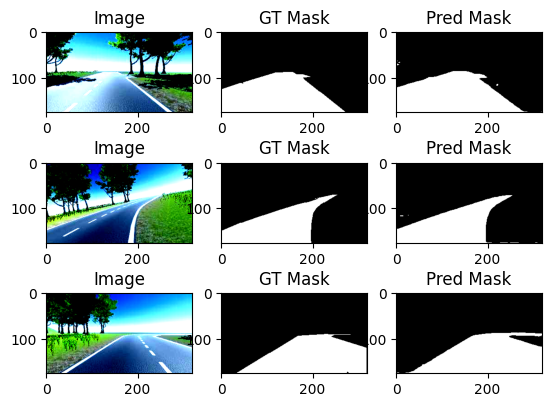

In [ ]:
model.eval()
with torch.no_grad():
    imgs, masks = next(iter(test_loader))
    imgs, masks = imgs.to(device), masks.to(device)
    imgs = imgs.float()
    outputs = torch.sigmoid(model(imgs)).cpu()  # giữ float để hiển thị
    preds = (outputs > 0.01).int()              # threshold 0/1

import matplotlib.pyplot as plt

for i in range(3):  # hiển thị 3 ảnh
    plt.subplot(3,3,i*3+1)
    plt.imshow(imgs[i].permute(1,2,0).cpu())  # nếu đã ToTensor() thì không /255
    plt.title("Image")

    plt.subplot(3,3,i*3+2)
    plt.imshow(masks[i].squeeze().cpu(), cmap='gray')
    plt.title("GT Mask")

    plt.subplot(3,3,i*3+3)
    plt.imshow(preds[i,0], cmap ="gray")
    plt.title("Pred Mask")
plt.show()


In [ ]:
print(imgs[i].min().item(), imgs[i].max().item())

-1.8439078330993652 2.6399998664855957


In [ ]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Tổng số tham số: {total_params}")
print(f"Số tham số có thể train: {trainable_params}")



Tổng số tham số: 31043521
Số tham số có thể train: 31043521


In [ ]:
torch.save(model.state_dict(), "/content/unet_modelv1.pth")


In [ ]:
!mkdir /content/drive/MyDrive/'Car racing  2025'/weight

mkdir: cannot create directory ‘/content/drive/MyDrive/Car racing  2025/weight’: File exists


In [29]:
!cp -r /content/unet_modelv1.pth /content/drive/MyDrive/'Car racing  2025'/weight/unet_modelv1.pth

#TEST

In [30]:
test_image_path = "/content/data/test/images/raw_00803_png.rf.ae3b72ad3faaccac21927b3d9956b174.jpg"

In [31]:
test_image = cv2.imread(test_image_path)

In [ ]:
from google.colab.patches import cv2_imshow
test_image = cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB) #anh cv2 type
cv2_imshow(test_image)
test_image = val_transform(image=test_image)["image"]
test_image = test_image.unsqueeze(0).to(device)

error: OpenCV(4.12.0) /io/opencv/modules/imgproc/src/color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'


In [33]:
test_output = torch.sigmoid(model(test_image)).cpu()

TypeError: conv2d() received an invalid combination of arguments - got (NoneType, Parameter, Parameter, tuple, tuple, tuple, int), but expected one of:
 * (Tensor input, Tensor weight, Tensor bias = None, tuple of ints stride = 1, tuple of ints padding = 0, tuple of ints dilation = 1, int groups = 1)
      didn't match because some of the arguments have invalid types: (!NoneType!, !Parameter!, !Parameter!, !tuple of (int, int)!, !tuple of (int, int)!, !tuple of (int, int)!, !int!)
 * (Tensor input, Tensor weight, Tensor bias = None, tuple of ints stride = 1, str padding = "valid", tuple of ints dilation = 1, int groups = 1)
      didn't match because some of the arguments have invalid types: (!NoneType!, !Parameter!, !Parameter!, !tuple of (int, int)!, !tuple of (int, int)!, !tuple of (int, int)!, !int!)


In [ ]:
pred_mask = test_output.squeeze().detach().numpy()


In [ ]:
    plt.subplot(3,3,1)
    plt.imshow(pred_mask, cmap ="gray")
    plt.title("Pred Mask")